In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
import os
import json
import random
import torch
import types
import matplotlib.pyplot as plt
import torch.nn as nn
import numpy as np
import pandas as pd
import torch.nn.functional as F
import seaborn as sns

from typing import Dict, Tuple, Optional
from tqdm.auto import tqdm
from datetime import datetime
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, log_loss, accuracy_score

In [3]:
# Canonical paths (match Notebook 08)
base_dir = "/content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M"
preprocessed_dir = f"{base_dir}/AntM2C_preprocessed"
checkpoints_dir = f"{base_dir}/checkpoints"
splits_dir = f"{preprocessed_dir}/splits"
split_features_dir = f"{preprocessed_dir}/split_features"

results_dir = f"{base_dir}/eval_results"
os.makedirs(results_dir, exist_ok=True)

In [4]:
# Artifact paths (Notebook 08 actual filenames)
model_ckpt_path = os.path.join(checkpoints_dir, "coldfusionx_model_epoch3.pt")
fusion_config_path = os.path.join(checkpoints_dir, "fusion_config.json")
meta_config_path = os.path.join(checkpoints_dir, "meta_config.json")
training_meta_path = os.path.join(checkpoints_dir, "training_meta_epoch3.json")

test_idx_path = os.path.join(splits_dir, "test_idx.npy")
val_idx_path = os.path.join(splits_dir, "val_idx.npy")

In [5]:
# Existence checks
required_paths = {
    "base_dir": base_dir,
    "preprocessed_dir": preprocessed_dir,
    "checkpoints_dir": checkpoints_dir,
    "splits_dir": splits_dir,
    "split_features_dir": split_features_dir,
    "results_dir": results_dir,
    "model_ckpt_path": model_ckpt_path,
    "fusion_config_path": fusion_config_path,
    "meta_config_path": meta_config_path,
    "training_meta_path": training_meta_path,
    "test_idx_path": test_idx_path,
}

In [6]:
missing = [k for k, p in required_paths.items() if not os.path.exists(p)]
if missing:
    print("Missing required paths:")
    for k in missing:
        print(f" - {k}: {required_paths[k]}")
    raise FileNotFoundError("One or more required files/folders are missing. Fix paths before continuing.")

In [7]:
# Reproducibility
SEED = 42           # consistent with Notebook 08
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

In [8]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [9]:
# Determinism flags (for evaluation reproducibility)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [10]:
# Load configs
with open(fusion_config_path, "r") as f:
    fusion_config = json.load(f)

with open(meta_config_path, "r") as f:
    meta_config = json.load(f)

with open(training_meta_path, "r") as f:
    training_meta = json.load(f)

In [11]:
# Load split indices
test_idx = np.load(test_idx_path)
val_idx = np.load(val_idx_path) if os.path.exists(val_idx_path) else None

In [12]:
# Extract key values (safe getters)
d_model = fusion_config.get("d_model", fusion_config.get("D_MODEL", None))
fewshot_n = meta_config.get("FEWSHOT_N", meta_config.get("fewshot_n", None))
num_scenes = fusion_config.get("num_scenes", fusion_config.get("NUM_SCENES", None))

batch_size = training_meta.get("batch_size", training_meta.get("BATCH_SIZE", None))

In [13]:
print("--- Key Config Values ---")
print("d_model:", d_model)
print("FEWSHOT_N:", fewshot_n)
print("num_scenes:", num_scenes)
print("batch_size (from training_meta):", batch_size)

print("\n--- Split Sizes ---")
print("test_idx:", len(test_idx))
print("val_idx:", len(val_idx) if val_idx is not None else "N/A (missing or not loaded)")

print("\n--- Paths ---")
for k, p in required_paths.items():
    print(f"{k}: {p}")

--- Key Config Values ---
d_model: 256
FEWSHOT_N: 10
num_scenes: 5
batch_size (from training_meta): 4096

--- Split Sizes ---
test_idx: 373033
val_idx: 373033

--- Paths ---
base_dir: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M
preprocessed_dir: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/AntM2C_preprocessed
checkpoints_dir: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/checkpoints
splits_dir: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/AntM2C_preprocessed/splits
split_features_dir: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/AntM2C_preprocessed/split_features
results_dir: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/eval_results
model_ckpt_path: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/checkpoints/coldfusionx_model_epoch3.pt
fusion_config_path: /content/driv

### Load Row-Aligned Evaluation Artifacts + Assert Alignment

In [ ]:
# Row-aligned artifacts (interaction-level)
df_id_path = os.path.join(split_features_dir, "df_id_encoded.pkl")
df_processed_path = os.path.join(preprocessed_dir, "df_processed.pkl")  # used for labels
text_embeddings_path = os.path.join(preprocessed_dir, "text_embeddings.npy")
time_features_path = os.path.join(preprocessed_dir, "time_features_final.pt")

In [ ]:
# Item-level artifacts (lookup by item_id_idx)
image_embeddings_path = os.path.join(base_dir, "image_embeddings_vit_base_aligned.pt")
image_missing_mask_path = os.path.join(base_dir, "image_missing_mask.pt")

In [ ]:
# Existence checks (fail early)
required_step1 = {
    "df_id_path": df_id_path,
    "df_processed_path": df_processed_path,
    "text_embeddings_path": text_embeddings_path,
    "time_features_path": time_features_path,
    "image_embeddings_path": image_embeddings_path,
    "image_missing_mask_path": image_missing_mask_path,
}

In [ ]:
missing_step1 = [k for k, p in required_step1.items() if not os.path.exists(p)]
if missing_step1:
    print("Missing artifacts:")
    for k in missing_step1:
        print(f" - {k}: {required_step1[k]}")
    raise FileNotFoundError("One or more Step 1 artifacts are missing. Fix paths before continuing.")

#### Load Artifacts (df_id, text memmap, time features, image tables, labels)

In [ ]:
# Load df_id_encoded.pkl
df_id = pd.read_pickle(df_id_path)

In [ ]:
# Load text embeddings (memmap)
text_memmap = np.load(text_embeddings_path, mmap_mode="r")

In [ ]:
# Load time features
time_features = torch.load(time_features_path, map_location="cpu")

In [ ]:
# Load item-level image embedding table + missing mask
image_embeddings = torch.load(image_embeddings_path, map_location="cpu")
image_missing_mask = torch.load(image_missing_mask_path, map_location="cpu")

In [ ]:
# Load labels (same approach as Notebook 08: detect column)
df_processed = pd.read_pickle(df_processed_path)

In [ ]:
label_col = "label"
labels = df_processed[label_col].to_numpy(dtype=np.float32)

#### Load Train Split + Build Train-Only Item Counts

In [ ]:
train_idx_path = os.path.join(splits_dir, "train_idx.npy")
train_idx = np.load(train_idx_path)

In [ ]:
# Ensure indices are integer type
train_idx = train_idx.astype(np.int64)

# FEWSHOT_N from meta_config (Notebook 08 standard)
FEWSHOT_N = int(meta_config["FEWSHOT_N"])

# Derive num_items from df_id (already verified)
num_items = int(df_id["item_id_idx"].max()) + 1

In [ ]:
# Extract train items and compute bincount (train-only exposure counts)
train_items = df_id.iloc[train_idx]["item_id_idx"].to_numpy(dtype=np.int64)
item_train_count = np.bincount(train_items, minlength=num_items).astype(np.int64)

# Sanity checks
assert item_train_count.shape[0] == num_items, "item_train_count length mismatch with num_items"
assert item_train_count.min() >= 0, "Negative counts detected (unexpected)"

In [ ]:
print("--- Train-only item counts computed. ---")
print("train_idx:", len(train_idx))
print("num_items:", num_items)
print("FEWSHOT_N:", FEWSHOT_N)

--- Train-only item counts computed. ---
train_idx: 2984263
num_items: 59142
FEWSHOT_N: 10


#### Summary Stats + Cold-Item Percentage

In [ ]:
# Summary statistics
min_count = int(item_train_count.min())
max_count = int(item_train_count.max())
mean_count = float(item_train_count.mean())
median_count = float(np.median(item_train_count))

In [ ]:
# How many items are "cold" by the few-shot definition (<= FEWSHOT_N exposures in train)
cold_items_mask = item_train_count <= FEWSHOT_N
num_cold_items = int(cold_items_mask.sum())
pct_cold_items = 100.0 * num_cold_items / num_items

# How many items are completely unseen in train (count == 0)
num_unseen_items = int((item_train_count == 0).sum())
pct_unseen_items = 100.0 * num_unseen_items / num_items

In [ ]:
# Distribution slices (useful for sanity checks)
num_1_5 = int(((item_train_count >= 1) & (item_train_count <= 5)).sum())
num_6_10 = int(((item_train_count >= 6) & (item_train_count <= 10)).sum())
num_11_50 = int(((item_train_count >= 11) & (item_train_count <= 50)).sum())
num_gt_50 = int((item_train_count > 50).sum())

In [ ]:
print("--- Train-only Count Summary ---")
print(f"Items (num_items): {num_items:,}")
print(f"Train interactions: {len(train_idx):,}")
print(f"Count stats: min={min_count}, median={median_count:.2f}, mean={mean_count:.2f}, max={max_count}")

print("\n--- Cold definition (train-only) ---")
print(f"FEWSHOT_N: {FEWSHOT_N}")
print(f"Cold items (count <= {FEWSHOT_N}): {num_cold_items:,} ({pct_cold_items:.2f}%)")
print(f"Unseen items (count == 0): {num_unseen_items:,} ({pct_unseen_items:.2f}%)")

print("\n--- Count buckets (train-only) ---")
print(f"1–5:   {num_1_5:,}")
print(f"6–10:  {num_6_10:,}")
print(f"11–50: {num_11_50:,}")
print(f">50:   {num_gt_50:,}")

--- Train-only Count Summary ---
Items (num_items): 59,142
Train interactions: 2,984,263
Count stats: min=0, median=2.00, mean=50.46, max=401813

--- Cold definition (train-only) ---
FEWSHOT_N: 10
Cold items (count <= 10): 44,959 (76.02%)
Unseen items (count == 0): 4,493 (7.60%)

--- Count buckets (train-only) ---
1–5:   35,065
6–10:  5,401
11–50: 8,712
>50:   5,471


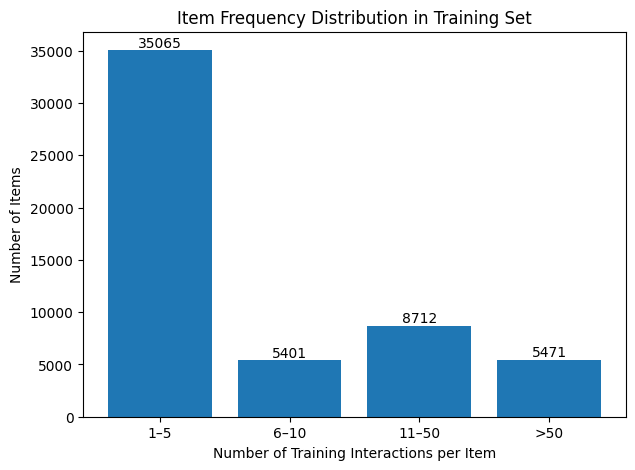

In [ ]:
# Distribution values
labels_dist = ['1–5', '6–10', '11–50', '>50']
counts = [num_1_5, num_6_10, num_11_50, num_gt_50]

plt.figure(figsize=(7, 5))
plt.bar(labels_dist, counts)
plt.xlabel("Number of Training Interactions per Item")
plt.ylabel("Number of Items")
plt.title("Item Frequency Distribution in Training Set")

# annotate counts on bars
for i, v in enumerate(counts):
    plt.text(i, v, str(v), ha='center', va='bottom')

plt.show()

In [ ]:
# ensure splits are disjoint (not overlapping)
test_set = set(test_idx.tolist())
train_set = set(train_idx.tolist())
val_set = set(val_idx.tolist()) if val_idx is not None else set()

overlap_train_test = len(train_set.intersection(test_set))
overlap_train_val = len(train_set.intersection(val_set))
overlap_val_test = len(val_set.intersection(test_set)) if val_idx is not None else 0

print("--- Split Integrity Check ---")
print("Overlap train ∩ test:", overlap_train_test)
print("Overlap train ∩ val :", overlap_train_val)
print("Overlap val ∩ test  :", overlap_val_test)

if overlap_train_test == 0 and overlap_train_val == 0 and overlap_val_test == 0:
    print("\nSplits appear disjoint.")
else:
    print("\nSplits overlap detected. This can invalidate cold_mask and evaluation.")

--- Split Integrity Check ---
Overlap train ∩ test: 0
Overlap train ∩ val : 0
Overlap val ∩ test  : 0

Splits appear disjoint.


#### Build Test Dataset + DataLoader (Evaluation Mode)

In [ ]:
# test_idx already loaded, double check dtype
test_idx = test_idx.astype(np.int64)

# Build item_is_fewshot using TRAIN-only counts (Notebook 08 logic)
# Cold definition: count <= FEWSHOT_N
item_is_fewshot = torch.tensor(item_train_count <= FEWSHOT_N, dtype=torch.bool)

print("item_is_fewshot:", item_is_fewshot.shape, "| cold_items:", int(item_is_fewshot.sum()))
print("test_idx:", test_idx.shape, "| example idx:", int(test_idx[0]))

item_is_fewshot: torch.Size([59142]) | cold_items: 44959
test_idx: (373033,) | example idx: 2296852


In [ ]:
# This class was already introduced in previous notebooks (copy pasting it here for reuse)
class CTRDataset(Dataset):
    """
    Row-aligned CTR dataset.

    Returns:
      user_id_idx: LongTensor ()
      item_id_idx: LongTensor ()
      scene_idx:   LongTensor ()
      text_vec:    FloatTensor (1536)
      time_vec:    FloatTensor (5)
      image_vec:   FloatTensor (768) (zero if missing)
      label:       FloatTensor ()
      cold_mask:   BoolTensor ()
    """
    def __init__(
        self,
        row_indices: np.ndarray,
        df_id: pd.DataFrame,
        text_embeddings_memmap: np.ndarray,
        time_features: torch.Tensor,
        image_embeddings: torch.Tensor,
        image_missing_mask: torch.Tensor,
        labels: np.ndarray,
        item_is_fewshot: torch.Tensor,
        item_train_count: np.ndarray,   # NEW
    ):
        self.row_indices = row_indices.astype(np.int64)
        self.df_id = df_id
        self.text_mem = text_embeddings_memmap
        self.time = time_features
        self.image = image_embeddings
        self.img_missing = image_missing_mask.bool()
        self.labels = labels
        self.item_is_fewshot = item_is_fewshot
        self.item_train_count = item_train_count

        self.text_dim = self.text_mem.shape[1]
        self.time_dim = self.time.shape[1]
        self.image_dim = self.image.shape[1]

    def __len__(self):
        return len(self.row_indices)

    def __getitem__(self, i: int):
        row_idx = int(self.row_indices[i])

        row = self.df_id.iloc[row_idx]
        user_idx = int(row["user_id_idx"])
        item_idx = int(row["item_id_idx"])
        scene_idx = int(row["scene_idx"])

        # Interaction-level features
        text_vec = torch.from_numpy(self.text_mem[row_idx].copy()).float()
        time_vec = self.time[row_idx].float()                                 # (5,)

        # Item-level image embedding (zero if missing)
        if bool(self.img_missing[item_idx].item()):
            image_vec = torch.zeros(self.image_dim, dtype=torch.float32)
        else:
            image_vec = self.image[item_idx].float()                          # (768,)

        # Label
        y = float(self.labels[row_idx])
        label = torch.tensor(y, dtype=torch.float32)

        item_count = torch.tensor(item_count, dtype=torch.long)

        # Cold mask (keep for reporting/metrics; no longer required for blending)
        cold_mask = bool(self.item_is_fewshot[item_idx])
        # Frequency count (TRAIN exposure count for this item)
        item_count = int(self.item_train_count[item_idx])

        return {
            "row_idx": torch.tensor(row_idx, dtype=torch.long),
            "user_idx": torch.tensor(user_idx, dtype=torch.long),
            "item_idx": torch.tensor(item_idx, dtype=torch.long),
            "scene_idx": torch.tensor(scene_idx, dtype=torch.long),
            "text_vec": text_vec,
            "time_vec": time_vec,
            "image_vec": image_vec,
            "label": label,
            "cold_mask": torch.tensor(cold_mask, dtype=torch.bool),
            "item_count": torch.tensor(item_count, dtype=torch.long),   # NEW
        }

In [ ]:
# Create test dataset (evaluation mode)
test_dataset = CTRDataset(
    row_indices=test_idx,
    df_id=df_id,
    text_embeddings_memmap=text_memmap,
    time_features=time_features if torch.is_tensor(time_features) else torch.tensor(time_features),
    image_embeddings=image_embeddings,
    image_missing_mask=image_missing_mask,
    labels= labels,
    item_is_fewshot=item_is_fewshot,
    item_train_count=item_train_count,
)

In [ ]:
# Create DataLoader (deterministic)
# Use training batch_size as a starting point (4096), but CPU may prefer smaller batches.
eval_batch_size = int(training_meta.get("batch_size", 4096))

In [ ]:
# If CPU evaluation is slow or memory tight
if device == "cpu":
    eval_batch_size = min(eval_batch_size, 1024)

In [ ]:
test_loader = DataLoader(
    test_dataset,
    batch_size=eval_batch_size,
    shuffle=False,
    pin_memory=(device == "cuda"),
    drop_last=False,
)

print("test_dataset length:", len(test_dataset))
print("test_loader batch_size:", eval_batch_size)

test_dataset length: 373033
test_loader batch_size: 4096


In [ ]:
# One-batch sanity check
batch = next(iter(test_loader))

In [ ]:
# Shapes
print("--- One-batch check ---")
for k in ["user_idx", "item_idx", "scene_idx", "text_vec", "time_vec", "image_vec", "label", "cold_mask", "item_count"]:
    v = batch[k]
    if torch.is_tensor(v):
        print(f"{k:10s} shape={tuple(v.shape)} dtype={v.dtype}")
    else:
        print(f"{k:10s} type={type(v)}")

--- One-batch check ---
user_idx   shape=(4096,) dtype=torch.int64
item_idx   shape=(4096,) dtype=torch.int64
scene_idx  shape=(4096,) dtype=torch.int64
text_vec   shape=(4096, 1536) dtype=torch.float32
time_vec   shape=(4096, 5) dtype=torch.float32
image_vec  shape=(4096, 768) dtype=torch.float32
label      shape=(4096,) dtype=torch.float32
cold_mask  shape=(4096,) dtype=torch.bool
item_count shape=(4096,) dtype=torch.int64


In [ ]:
# Rates
cold_rate = float(batch["cold_mask"].float().mean())
pos_rate = float(batch["label"].float().mean())

print("Batch cold rate:", cold_rate)
print("Batch positive rate:", pos_rate)

Batch cold rate: 0.042236328125
Batch positive rate: 0.32861328125


In [ ]:
# Quick correctness checks
assert batch["text_vec"].shape[1] == 1536, "text_vec dim mismatch"
assert batch["time_vec"].shape[1] == 5, "time_vec dim mismatch"
assert batch["image_vec"].shape[1] == 768, "image_vec dim mismatch"

#### Rebuild Model and Load Checkpoint
(Copy pasting from the implementation in Notebook 08)

In [ ]:
# from Notebook 06
class ModalityAttentionFusion(nn.Module):
    """
    Projects {id, text, image, time} into a shared d_model space and applies
    per-sample attention over modalities.

    Forward inputs:
      id_vec:    (B, id_dim)
      text_vec:  (B, text_dim=1536)
      image_vec: (B, image_dim=768)
      time_vec:  (B, time_dim=5 or Time2Vec dim later)

    Output:
      fused: (B, d_model)

    Diagnostics:
      get_last_attention() returns a dict of attention weights.
    """
    def __init__(
        self,
        id_dim: int,
        text_dim: int,
        image_dim: int,
        time_dim: int,
        d_model: int = 256,
        attn_hidden: int = 128,
        dropout: float = 0.1
    ):
        super().__init__()

        # Projections into shared d_model
        self.proj_id = nn.Sequential(
            nn.Linear(id_dim, d_model),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.proj_text = nn.Sequential(
            nn.Linear(text_dim, d_model),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.proj_image = nn.Sequential(
            nn.Linear(image_dim, d_model),
            nn.ReLU(),
            nn.Dropout(dropout),
        )
        self.proj_time = nn.Sequential(
            nn.Linear(time_dim, d_model),
            nn.ReLU(),
            nn.Dropout(dropout),
        )

        # Attention MLP produces 1 scalar score per modality per sample
        self.attn_mlp = nn.Sequential(
            nn.Linear(d_model, attn_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(attn_hidden, 1)
        )

        self._last_attention: Optional[Dict[str, torch.Tensor]] = None

    def forward(
        self,
        id_vec: torch.Tensor,
        text_vec: torch.Tensor,
        image_vec: torch.Tensor,
        time_vec: torch.Tensor
    ) -> torch.Tensor:

        # Project each modality to (B, d_model)
        z_id = self.proj_id(id_vec)
        z_text = self.proj_text(text_vec)
        z_image = self.proj_image(image_vec)
        z_time = self.proj_time(time_vec)

        # Stack: (B, M=4, d_model)
        Z = torch.stack([z_id, z_text, z_image, z_time], dim=1)

        # Compute attention logits per modality: (B, 4, 1) -> (B, 4)
        logits = self.attn_mlp(Z).squeeze(-1)

        # Softmax over modalities -> (B, 4)
        attn = F.softmax(logits, dim=1)

        # Weighted sum: (B, 4, 1) * (B, 4, d_model) -> (B, d_model)
        fused = torch.sum(attn.unsqueeze(-1) * Z, dim=1)

        # Save for diagnostics (detach for safe logging)
        self._last_attention = {
            "id": attn[:, 0].detach(),
            "text": attn[:, 1].detach(),
            "image": attn[:, 2].detach(),
            "time": attn[:, 3].detach(),
        }

        return fused

    def get_last_attention(self) -> Optional[Dict[str, torch.Tensor]]:
        return self._last_attention

In [ ]:
# from notbook 06
class ScenarioAwareMMoE(nn.Module):
    """
    Scenario-aware Mixture-of-Experts (MMoE).

    Inputs:
      x:        (B, d_model)   fused representation
      scene_idx:(B,)           scenario indices (0..num_scenes-1)

    Outputs:
      y:        (B, hidden_dim) combined expert output

    Diagnostics:
      get_last_gates(): returns gate weights (B, num_experts)
    """
    def __init__(
        self,
        d_model: int,
        hidden_dim: int,
        num_experts: int,
        num_scenes: int,
        gate_embed_dim: int = 16,
        expert_dropout: float = 0.1
    ):
        super().__init__()

        self.d_model = d_model
        self.hidden_dim = hidden_dim
        self.num_experts = num_experts
        self.num_scenes = num_scenes

        # Experts: each expert maps (B, d_model) -> (B, hidden_dim)
        self.experts = nn.ModuleList([
            nn.Sequential(
                nn.Linear(d_model, hidden_dim),
                nn.ReLU(),
                nn.Dropout(expert_dropout),
                nn.Linear(hidden_dim, hidden_dim),
                nn.ReLU(),
                nn.Dropout(expert_dropout),
            )
            for _ in range(num_experts)
        ])

        # Scene embedding used for gating
        self.scene_embed = nn.Embedding(num_scenes, gate_embed_dim)

        # Gate network: conditioned on scene embedding (optionally we can include x too later)
        self.gate = nn.Sequential(
            nn.Linear(gate_embed_dim, gate_embed_dim),
            nn.ReLU(),
            nn.Linear(gate_embed_dim, num_experts)
        )

        self._last_gates: Optional[torch.Tensor] = None

    def forward(self, x: torch.Tensor, scene_idx: torch.Tensor) -> torch.Tensor:
        """
        Args:
            x: (B, d_model)
            scene_idx: (B,)
        Returns:
            y: (B, hidden_dim)
        """
        B = x.size(0)

        # Expert outputs: list of (B, hidden_dim) -> stack -> (B, E, hidden_dim)
        expert_outputs = torch.stack([expert(x) for expert in self.experts], dim=1)

        # Compute gate weights conditioned on scene_idx
        s_emb = self.scene_embed(scene_idx)           # (B, gate_embed_dim)
        gate_logits = self.gate(s_emb)                # (B, num_experts)
        gates = F.softmax(gate_logits, dim=-1)        # (B, num_experts)

        # Combine experts: (B, E, 1) * (B, E, hidden_dim) -> (B, hidden_dim)
        y = torch.sum(gates.unsqueeze(-1) * expert_outputs, dim=1)

        # Store for diagnostics
        self._last_gates = gates.detach()

        return y

    def get_last_gates(self) -> Optional[torch.Tensor]:
        return self._last_gates

In [ ]:
# from notebook 07
class IDEmbeddingLayer(nn.Module):
    """
    Embedding tables for user/item/scene.
    Produces user_emb, item_emb, scene_emb.
    """
    def __init__(self, num_users: int, num_items: int, num_scenes: int,
                 id_dim: int = 256, scene_dim: int = 32, dropout: float = 0.0):
        super().__init__()
        self.user_emb = nn.Embedding(num_users, id_dim)
        self.item_emb = nn.Embedding(num_items, id_dim)
        self.scene_emb = nn.Embedding(num_scenes, scene_dim)

        self.dropout = nn.Dropout(dropout)

    def forward(self, user_idx: torch.Tensor, item_idx: torch.Tensor, scene_idx: torch.Tensor):
        u = self.dropout(self.user_emb(user_idx))
        i = self.dropout(self.item_emb(item_idx))
        s = self.dropout(self.scene_emb(scene_idx))
        return u, i, s

In [ ]:
# from notebook 07
class ItemBlendModule(nn.Module):
    """
    Smooth alpha blending based on TRAIN item frequency.

    alpha in [0,1] increases with item exposure count:
      - low count  -> alpha closer to 0 (more meta)
      - high count -> alpha closer to 1 (more ID)
    """
    def __init__(self, fewshot_n: int):
        super().__init__()
        self.fewshot_n = int(fewshot_n)
        self._last_alpha = None

    def forward(
        self,
        item_id_emb: torch.Tensor,     # (B, D)
        item_meta_emb: torch.Tensor,   # (B, D)
        item_count: torch.Tensor       # (B,)
    ) -> torch.Tensor:

        # Smooth alpha: log-scaled by threshold (robust, bounded)
        alpha = torch.log1p(item_count.float()) / np.log1p(self.fewshot_n)
        alpha = torch.clamp(alpha, 0.0, 1.0).unsqueeze(1)  # (B,1)

        item_final = alpha * item_id_emb + (1.0 - alpha) * item_meta_emb
        self._last_alpha = alpha.detach()
        return item_final

    def get_last_alpha(self):
        return self._last_alpha

In [ ]:
# from notebook 07
class MetaEmbeddingGenerator(nn.Module):
    """
    Generates meta_item_emb from non-ID modalities: text, image, time
    using projection layers + per-sample modality attention.
    """
    def __init__(
        self,
        text_dim: int,
        image_dim: int,
        time_dim: int,
        meta_dim: int = 256,
        attn_hidden: int = 128,
        dropout: float = 0.1,
        use_scene: bool = False,
        num_scenes: int = 0,
        scene_emb_dim: int = 16
    ):
        super().__init__()
        self.meta_dim = meta_dim
        self.use_scene = use_scene

        # Projections into shared space
        self.proj_text = nn.Sequential(
            nn.Linear(text_dim, meta_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        self.proj_image = nn.Sequential(
            nn.Linear(image_dim, meta_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        self.proj_time = nn.Sequential(
            nn.Linear(time_dim, meta_dim),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # Optional scene conditioning (lightweight)
        if self.use_scene:
            assert num_scenes > 0, "num_scenes must be provided if use_scene=True"
            self.scene_emb = nn.Embedding(num_scenes, scene_emb_dim)
            attn_in = meta_dim + scene_emb_dim
        else:
            attn_in = meta_dim

        # Attention scoring network (shared across modalities)
        self.attn_mlp = nn.Sequential(
            nn.Linear(attn_in, attn_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(attn_hidden, 1)
        )

        self._last_attention = None  # diagnostics

    def forward(
        self,
        text_vec: torch.Tensor,   # (B, text_dim)
        image_vec: torch.Tensor,  # (B, image_dim)
        time_vec: torch.Tensor,   # (B, time_dim)
        scene_idx: torch.Tensor = None  # optional (B,)
    ) -> torch.Tensor:
        B = text_vec.size(0)

        # Project modalities to (B, meta_dim)
        z_text  = self.proj_text(text_vec)
        z_image = self.proj_image(image_vec)
        z_time  = self.proj_time(time_vec)

        # Stack into (B, M, meta_dim) where M=3 modalities
        Z = torch.stack([z_text, z_image, z_time], dim=1)  # (B, 3, meta_dim)

        if self.use_scene:
            assert scene_idx is not None, "scene_idx required when use_scene=True"
            s = self.scene_emb(scene_idx)                   # (B, scene_emb_dim)
            s = s.unsqueeze(1).expand(B, 3, s.size(-1))     # (B, 3, scene_emb_dim)
            Z_attn_in = torch.cat([Z, s], dim=-1)           # (B, 3, meta_dim+scene_emb_dim)
        else:
            Z_attn_in = Z                                   # (B, 3, meta_dim)

        # Compute attention logits per modality: (B, 3, 1) -> (B, 3)
        attn_logits = self.attn_mlp(Z_attn_in).squeeze(-1)  # (B, 3)
        attn_weights = F.softmax(attn_logits, dim=1)        # (B, 3)

        # Weighted sum to get meta embedding: (B, meta_dim)
        meta_item_emb = torch.sum(Z * attn_weights.unsqueeze(-1), dim=1)

        # Store attention for diagnostics
        self._last_attention = {
            "text": attn_weights[:, 0].detach(),
            "image": attn_weights[:, 1].detach(),
            "time": attn_weights[:, 2].detach()
        }

        return meta_item_emb

    def get_last_attention(self):
        return self._last_attention

In [ ]:
class CTRHead(nn.Module):
    def __init__(self, input_dim=256, hidden_dim=256, dropout=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1)  # logit
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)  # (B,)

In [ ]:
class ColdFusionXModel(nn.Module):
    def __init__(self, fusion_config, meta_config, dropout=0.1, scene_dim=32):
        super().__init__()

        # Configs
        self.num_users = int(fusion_config["num_users"])
        self.num_items = int(fusion_config["num_items"])
        self.num_scenes = int(fusion_config["num_scenes"])

        self.text_dim = int(fusion_config["text_dim"])
        self.image_dim = int(fusion_config["image_dim"])
        self.time_dim = int(fusion_config["time_dim"])

        self.d_model = int(fusion_config["d_model"])
        self.hidden_dim = int(fusion_config["hidden_dim"])
        self.num_experts = int(fusion_config["num_experts"])

        self.meta_dim = int(meta_config["meta_dim"])
        assert self.meta_dim == self.d_model, "Recommended: meta_dim should match d_model."

        # 1) ID embeddings (from Notebook 06/07 class)
        self.id_layer = IDEmbeddingLayer(
            num_users=self.num_users,
            num_items=self.num_items,
            num_scenes=self.num_scenes,
            id_dim=self.d_model,
            scene_dim=scene_dim,
            dropout=dropout
        )

        # 2) Meta embedding generator (from Notebook 07 class)
        self.meta_gen = MetaEmbeddingGenerator(
            text_dim=self.text_dim,
            image_dim=self.image_dim,
            time_dim=self.time_dim,
            meta_dim=self.meta_dim,
            attn_hidden=128,
            dropout=dropout,
            use_scene=False
        )

        # 3) α-blend (from Notebook 07 class)
        self.blender = ItemBlendModule(fewshot_n=int(meta_config["FEWSHOT_N"]))

        # Project concat([user_emb, item_final, scene_emb]) -> d_model
        self.id_proj = nn.Sequential(
            nn.Linear(self.d_model + self.d_model + scene_dim, self.d_model),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # 4) Fusion (from Notebook 06 class)
        self.fusion = ModalityAttentionFusion(
            id_dim=self.d_model,
            text_dim=self.text_dim,
            image_dim=self.image_dim,
            time_dim=self.time_dim,
            d_model=self.d_model,
            attn_hidden=128,
            dropout=dropout
        )

        # 5) Scenario-aware routing (from Notebook 06 class signature)
        self.mmoe = ScenarioAwareMMoE(
            d_model=self.d_model,
            hidden_dim=self.hidden_dim,
            num_experts=self.num_experts,
            num_scenes=self.num_scenes,
            gate_embed_dim=16,
            expert_dropout=dropout
        )

        # 6) CTR head
        self.head = CTRHead(
            input_dim=self.hidden_dim,
            hidden_dim=self.hidden_dim,
            dropout=dropout
            )

        # Diagnostics handles
        self._last_alpha = None

    def forward(self, user_idx, item_idx, scene_idx, text_vec, image_vec, time_vec, cold_mask, item_count):
        # ID embeddings
        user_emb, item_id_emb, scene_emb = self.id_layer(
            user_idx,
            item_idx,
            scene_idx
            )

        # Meta item embedding
        item_meta_emb = self.meta_gen(
            text_vec=text_vec,
            image_vec=image_vec,
            time_vec=time_vec
            )

        # Unified item embedding (smooth α blend)
        item_final = self.blender(
            item_id_emb=item_id_emb,
            item_meta_emb=item_meta_emb,
            item_count=item_count
            )
        self._last_alpha = self.blender.get_last_alpha()

        # Build id_vec
        id_concat = torch.cat([user_emb, item_final, scene_emb], dim=1)
        id_vec = self.id_proj(id_concat)

        # Fusion + routing
        fused = self.fusion(
            id_vec=id_vec,
            text_vec=text_vec,
            image_vec=image_vec,
            time_vec=time_vec
            )
        routed = self.mmoe(fused, scene_idx)

        # Logit
        logit = self.head(routed)
        return logit

    # Diagnostics helpers (match internal storage types)
    def get_last_alpha(self):
        return self._last_alpha

    def get_last_fusion_attention(self):
        return self.fusion.get_last_attention()  # dict with keys id/text/image/time

    def get_last_meta_attention(self):
        return self.meta_gen.get_last_attention()  # dict with keys text/image/time

    def get_last_gates(self):
        return self.mmoe.get_last_gates()  # (B, num_experts)

In [ ]:
# Rebuild model using the same configs saved in Notebook 08
model = ColdFusionXModel(
    fusion_config=fusion_config,
    meta_config=meta_config,
    dropout=float(fusion_config.get("dropout", 0.1)),  # fallback if not present
    scene_dim=int(fusion_config.get("scene_dim", 32)), # fallback if not present
)

In [ ]:
# Load checkpoint safely
state = torch.load(model_ckpt_path, map_location=device)

In [ ]:
if isinstance(state, dict) and all(isinstance(k, str) for k in state.keys()):
    # direct state_dict
    state_dict = state
else:
    raise ValueError("Unrecognized checkpoint format. Expected a state_dict or dict wrapper.")

print("Checkpoint keys:", list(state_dict.keys()))

Checkpoint keys: ['id_layer.user_emb.weight', 'id_layer.item_emb.weight', 'id_layer.scene_emb.weight', 'meta_gen.proj_text.0.weight', 'meta_gen.proj_text.0.bias', 'meta_gen.proj_image.0.weight', 'meta_gen.proj_image.0.bias', 'meta_gen.proj_time.0.weight', 'meta_gen.proj_time.0.bias', 'meta_gen.attn_mlp.0.weight', 'meta_gen.attn_mlp.0.bias', 'meta_gen.attn_mlp.3.weight', 'meta_gen.attn_mlp.3.bias', 'id_proj.0.weight', 'id_proj.0.bias', 'fusion.proj_id.0.weight', 'fusion.proj_id.0.bias', 'fusion.proj_text.0.weight', 'fusion.proj_text.0.bias', 'fusion.proj_image.0.weight', 'fusion.proj_image.0.bias', 'fusion.proj_time.0.weight', 'fusion.proj_time.0.bias', 'fusion.attn_mlp.0.weight', 'fusion.attn_mlp.0.bias', 'fusion.attn_mlp.3.weight', 'fusion.attn_mlp.3.bias', 'mmoe.experts.0.0.weight', 'mmoe.experts.0.0.bias', 'mmoe.experts.0.3.weight', 'mmoe.experts.0.3.bias', 'mmoe.experts.1.0.weight', 'mmoe.experts.1.0.bias', 'mmoe.experts.1.3.weight', 'mmoe.experts.1.3.bias', 'mmoe.experts.2.0.weigh

In [ ]:
# Strict loading: capture missing/unexpected keys
missing_keys, unexpected_keys = model.load_state_dict(state_dict, strict=False)

In [ ]:
# Move model to device and set eval mode
model.to(device)
model.eval()

ColdFusionXModel(
  (id_layer): IDEmbeddingLayer(
    (user_emb): Embedding(67615, 256)
    (item_emb): Embedding(59142, 256)
    (scene_emb): Embedding(5, 32)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (meta_gen): MetaEmbeddingGenerator(
    (proj_text): Sequential(
      (0): Linear(in_features=1536, out_features=256, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
    )
    (proj_image): Sequential(
      (0): Linear(in_features=768, out_features=256, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
    )
    (proj_time): Sequential(
      (0): Linear(in_features=5, out_features=256, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
    )
    (attn_mlp): Sequential(
      (0): Linear(in_features=256, out_features=128, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
      (3): Linear(in_features=128, out_features=1, bias=True)
    )
  )
  (blender): ItemBlendModule()
  (id_proj): Sequential(


In [ ]:
print("Model instantiated and checkpoint loaded.")
print("Device:", device)
print("Missing keys:", len(missing_keys))
print("Unexpected keys:", len(unexpected_keys))

Model instantiated and checkpoint loaded.
Device: cuda
Missing keys: 0
Unexpected keys: 0


In [ ]:
# Confirm parameter count (for reporting)
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model.parameters())

print("--- Model Parameter Summary ---")
print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

--- Model Parameter Summary ---
Total parameters:     34,497,863
Trainable parameters: 34,497,863


In [ ]:
# One forward pass sanity check on a single batch
batch = next(iter(test_loader))

In [ ]:
with torch.no_grad():
    logit = model(
        user_idx=batch["user_idx"].to(device),
        item_idx=batch["item_idx"].to(device),
        scene_idx=batch["scene_idx"].to(device),
        text_vec=batch["text_vec"].to(device),
        image_vec=batch["image_vec"].to(device),
        time_vec=batch["time_vec"].to(device),
        cold_mask=batch["cold_mask"].to(device),      # not used in forward, but keep signature stable
        item_count=batch["item_count"].to(device),
    )

print("Forward pass DONE.")
print("logit shape:", tuple(logit.shape), "| dtype:", logit.dtype)
print("logit stats: min/max/mean:",
      float(logit.min()), float(logit.max()), float(logit.mean()))

Forward pass DONE.
logit shape: (4096,) | dtype: torch.float32
logit stats: min/max/mean: -17.09496307373047 5.697764873504639 -1.7306170463562012


In [ ]:
# confirm diagnostics are populated
alpha = model.get_last_alpha()
gates = model.get_last_gates()
fusion_attn = model.get_last_fusion_attention()
meta_attn = model.get_last_meta_attention()

print("--- Diagnostics (sample) ---")
print("alpha:", None if alpha is None else tuple(alpha.shape))
print("gates:", None if gates is None else tuple(gates.shape))
print("fusion_attn keys:", None if fusion_attn is None else list(fusion_attn.keys()))
print("meta_attn keys:", None if meta_attn is None else list(meta_attn.keys()))

--- Diagnostics (sample) ---
alpha: (4096, 1)
gates: (4096, 4)
fusion_attn keys: ['id', 'text', 'image', 'time']
meta_attn keys: ['text', 'image', 'time']


####  Run Test Inference (Collect Predictions + Diagnostics)

(Here we do a full test inference and collect outputs)

In [ ]:
def stable_sigmoid_from_logits(logits: np.ndarray) -> np.ndarray:
    """
    Numerically stable sigmoid for numpy arrays.
    Equivalent to expit, but implemented explicitly to avoid overflow.
    """
    out = np.empty_like(logits, dtype=np.float32)
    pos = logits >= 0
    neg = ~pos
    out[pos] = 1.0 / (1.0 + np.exp(-logits[pos]))
    exp_x = np.exp(logits[neg])
    out[neg] = exp_x / (1.0 + exp_x)
    return out

In [ ]:
# Storage (lists -> concatenated at end)
y_true_list = []
y_logit_list = []
cold_mask_list = []
scene_idx_list = []

# diagnostics (To analyze in Notebook 10)
alpha_list = []
gates_list = []

In [ ]:
model.eval()

ColdFusionXModel(
  (id_layer): IDEmbeddingLayer(
    (user_emb): Embedding(67615, 256)
    (item_emb): Embedding(59142, 256)
    (scene_emb): Embedding(5, 32)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (meta_gen): MetaEmbeddingGenerator(
    (proj_text): Sequential(
      (0): Linear(in_features=1536, out_features=256, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
    )
    (proj_image): Sequential(
      (0): Linear(in_features=768, out_features=256, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
    )
    (proj_time): Sequential(
      (0): Linear(in_features=5, out_features=256, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
    )
    (attn_mlp): Sequential(
      (0): Linear(in_features=256, out_features=128, bias=True)
      (1): ReLU()
      (2): Dropout(p=0.1, inplace=False)
      (3): Linear(in_features=128, out_features=1, bias=True)
    )
  )
  (blender): ItemBlendModule()
  (id_proj): Sequential(


In [ ]:
with torch.no_grad():
    for batch in tqdm(test_loader, desc="Inference (test)"):
        user_idx  = batch["user_idx"].to(device, non_blocking=True)
        item_idx  = batch["item_idx"].to(device, non_blocking=True)
        scene_idx = batch["scene_idx"].to(device, non_blocking=True)

        text_vec  = batch["text_vec"].to(device, non_blocking=True)
        image_vec = batch["image_vec"].to(device, non_blocking=True)
        time_vec  = batch["time_vec"].to(device, non_blocking=True)

        cold_mask = batch["cold_mask"]  # keep on CPU for saving
        item_count = batch["item_count"].to(device, non_blocking=True)

        # Forward pass
        logits = model(
            user_idx=user_idx,
            item_idx=item_idx,
            scene_idx=scene_idx,
            text_vec=text_vec,
            image_vec=image_vec,
            time_vec=time_vec,
            cold_mask=batch["cold_mask"].to(device, non_blocking=True),  # signature stability
            item_count=item_count,
        )

        # Collect predictions (move to CPU)
        y_logit_list.append(logits.detach().float().cpu().numpy())
        y_true_list.append(batch["label"].detach().float().cpu().numpy())
        cold_mask_list.append(cold_mask.detach().cpu().numpy().astype(np.bool_))
        scene_idx_list.append(batch["scene_idx"].detach().cpu().numpy().astype(np.int64))

        # diagnostics
        alpha = model.get_last_alpha()
        gates = model.get_last_gates()

        if alpha is not None:
            alpha_list.append(alpha.detach().float().cpu().numpy())   # (B,1)
        if gates is not None:
            gates_list.append(gates.detach().float().cpu().numpy())   # (B,E)

Inference (test):   0%|          | 0/92 [00:00<?, ?it/s]

In [ ]:
# Concatenate
y_true = np.concatenate(y_true_list, axis=0).astype(np.float32)
y_logit = np.concatenate(y_logit_list, axis=0).astype(np.float32)
cold_mask_arr = np.concatenate(cold_mask_list, axis=0).astype(np.bool_)
scene_idx_arr = np.concatenate(scene_idx_list, axis=0).astype(np.int64)

alpha_arr = np.concatenate(alpha_list, axis=0).astype(np.float32) if len(alpha_list) > 0 else None
gates_arr = np.concatenate(gates_list, axis=0).astype(np.float32) if len(gates_list) > 0 else None

In [ ]:
# Convert logits -> probabilities (stable)
y_prob = stable_sigmoid_from_logits(y_logit)

print("Inference collection complete.")
print("Collected:", len(y_true), "rows")

Inference collection complete.
Collected: 373033 rows


In [ ]:
# Integrity checks
assert len(y_true) == len(test_idx), f"y_true len {len(y_true)} != test_idx len {len(test_idx)}"
assert len(y_logit) == len(test_idx), f"y_logit len {len(y_logit)} != test_idx len {len(test_idx)}"
assert len(cold_mask_arr) == len(test_idx), "cold_mask length mismatch"
assert len(scene_idx_arr) == len(test_idx), "scene_idx length mismatch"
assert len(y_prob) == len(test_idx), "y_prob length mismatch"

In [ ]:
# Summary stats
logit_min, logit_max, logit_mean = float(y_logit.min()), float(y_logit.max()), float(y_logit.mean())
test_cold_rate = float(cold_mask_arr.mean())
test_pos_rate = float(y_true.mean())

print("--- Inference Summary ---")
print("N test:", len(test_idx))
print(f"logits: min={logit_min:.4f}, max={logit_max:.4f}, mean={logit_mean:.4f}")
print(f"test cold rate: {test_cold_rate:.4f}")
print(f"test positive rate: {test_pos_rate:.4f}")

--- Inference Summary ---
N test: 373033
logits: min=-20.3896, max=5.7565, mean=-1.7178
test cold rate: 0.0390
test positive rate: 0.3368


In [ ]:
print("alpha:", alpha_arr.shape, "| min/max/mean:",
          float(alpha_arr.min()), float(alpha_arr.max()), float(alpha_arr.mean()))

print("gates:", gates_arr.shape, "| per-row sum mean:",
          float(gates_arr.sum(axis=1).mean()))

alpha: (373033, 1) | min/max/mean: 0.0 1.0 0.9831495881080627
gates: (373033, 4) | per-row sum mean: 1.0


In [ ]:
save_path = os.path.join(results_dir, "test_predictions.npz")

save_kwargs = {
    "y_true": y_true,
    "y_logit": y_logit,
    "y_prob": y_prob,
    "cold_mask": cold_mask_arr,
    "scene_idx": scene_idx_arr,
}

# diagnostics
save_kwargs["alpha"] = alpha_arr
save_kwargs["gates"] = gates_arr

np.savez_compressed(save_path, **save_kwargs)

print("Saved to:", save_path)
print("Saved keys:", list(save_kwargs.keys()))

Saved to: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/eval_results/test_predictions.npz
Saved keys: ['y_true', 'y_logit', 'y_prob', 'cold_mask', 'scene_idx', 'alpha', 'gates']


### Evaluation Begins...

#### Compute Primary Metrics (Overall + Cold/Warm)
(This component is made independent of the previous component to save computing units, we'll be loading the saved predictions directly)

In [ ]:
# Load predictions saved in Step 5
pred_path = os.path.join(results_dir, "test_predictions.npz")
data = np.load(pred_path)

In [ ]:
y_true = data["y_true"].astype(np.float32)
y_logit = data["y_logit"].astype(np.float32)
y_prob = data["y_prob"].astype(np.float32)
cold_mask = data["cold_mask"].astype(bool)
scene_idx = data["scene_idx"].astype(np.int64)

N_total = len(y_true)
N_cold = int(cold_mask.sum())
N_warm = int((~cold_mask).sum())

In [ ]:
def compute_metrics(y_true, y_prob, threshold=0.5):
    """
    Returns AUC, LogLoss, Accuracy.
    Handles edge cases safely.
    """
    metrics = {}
    # AUC requires both classes present
    if len(np.unique(y_true)) >= 2:
        metrics["auc"] = float(roc_auc_score(y_true, y_prob))
    else:
        metrics["auc"] = np.nan

    # LogLoss (clip probs for safety)
    p = np.clip(y_prob, 1e-7, 1 - 1e-7)
    metrics["logloss"] = float(log_loss(y_true, p))

    # Accuracy at fixed threshold
    y_pred = (y_prob >= threshold).astype(np.int32)
    metrics["accuracy"] = float(accuracy_score(y_true, y_pred))
    return metrics

In [ ]:
# Overall results
overall_metrics = compute_metrics(y_true, y_prob)

# Cold-only results
cold_metrics = compute_metrics(
    y_true[cold_mask],
    y_prob[cold_mask]
)

# Warm-only results
warm_metrics = compute_metrics(
    y_true[~cold_mask],
    y_prob[~cold_mask]
)

# Counts and positive rates
summary = {
    "counts": {
        "N_total": int(N_total),
        "N_cold": int(N_cold),
        "N_warm": int(N_warm),
    },
    "positive_rates": {
        "overall": float(y_true.mean()),
        "cold": float(y_true[cold_mask].mean()) if N_cold > 0 else np.nan,
        "warm": float(y_true[~cold_mask].mean()) if N_warm > 0 else np.nan,
    },
    "metrics": {
        "overall": overall_metrics,
        "cold": cold_metrics,
        "warm": warm_metrics,
    }
}

In [ ]:
print("--- Primary Metrics (Test Set) ---")
print(f"N_total={N_total:,} | N_cold={N_cold:,} | N_warm={N_warm:,}")
print("\nPositive rates:")
print(f"  overall: {summary['positive_rates']['overall']:.4f}")
print(f"  cold:    {summary['positive_rates']['cold']:.4f}")
print(f"  warm:    {summary['positive_rates']['warm']:.4f}")

print("\nMetrics:")
print("  Overall -> AUC={auc:.4f}, LogLoss={logloss:.4f}, Acc={accuracy:.4f}".format(**overall_metrics))
print("  Cold    -> AUC={auc:.4f}, LogLoss={logloss:.4f}, Acc={accuracy:.4f}".format(**cold_metrics))
print("  Warm    -> AUC={auc:.4f}, LogLoss={logloss:.4f}, Acc={accuracy:.4f}".format(**warm_metrics))

--- Primary Metrics (Test Set) ---
N_total=373,033 | N_cold=14,539 | N_warm=358,494

Positive rates:
  overall: 0.3368
  cold:    0.1403
  warm:    0.3447

Metrics:
  Overall -> AUC=0.9194, LogLoss=0.3372, Acc=0.8512
  Cold    -> AUC=0.8418, LogLoss=0.3049, Acc=0.8774
  Warm    -> AUC=0.9200, LogLoss=0.3385, Acc=0.8502


In [ ]:
def bootstrap_auc_ci(y_true, y_prob, n_boot=1000, alpha=0.05, seed=42):
    """
    Percentile bootstrap CI for ROC-AUC.
    """
    rng = np.random.default_rng(seed)
    aucs = []
    n = len(y_true)

    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        yt = y_true[idx]
        yp = y_prob[idx]
        if len(np.unique(yt)) < 2:
            continue
        aucs.append(roc_auc_score(yt, yp))

    aucs = np.array(aucs)
    if len(aucs) == 0:
        return {"auc_mean": np.nan, "ci_low": np.nan, "ci_high": np.nan}

    lo = np.percentile(aucs, 100 * (alpha / 2))
    hi = np.percentile(aucs, 100 * (1 - alpha / 2))
    return {
        "auc_mean": float(aucs.mean()),
        "ci_low": float(lo),
        "ci_high": float(hi),
    }

In [ ]:
# Compute CIs (overall + cold)
ci_overall = bootstrap_auc_ci(y_true, y_prob, n_boot=500)
ci_cold = bootstrap_auc_ci(y_true[cold_mask], y_prob[cold_mask], n_boot=500) if N_cold > 0 else None

summary["auc_ci"] = {
    "overall": ci_overall,
    "cold": ci_cold,
}

print("AUC Confidence Intervals (bootstrap):")
print("  Overall:", ci_overall)
print("  Cold:   ", ci_cold)

AUC Confidence Intervals (bootstrap):
  Overall: {'auc_mean': 0.9193614816330855, 'ci_low': 0.9184482300402195, 'ci_high': 0.9202134610146421}
  Cold:    {'auc_mean': 0.8416248735677376, 'ci_low': 0.8321006434738522, 'ci_high': 0.8512481103981565}


The model achieves strong overall ranking performance (AUC = 0.919), while maintaining strong cold-start effectiveness (AUC = 0.842), indicating that the unified meta-embedding and scenario-aware routing architecture generalises well under sparse item conditions.

In [ ]:
# Prepare data for plotting
metrics_data = {
    'Category': ['Overall', 'Cold'],
    'AUC_Mean': [summary['auc_ci']['overall']['auc_mean'], summary['auc_ci']['cold']['auc_mean']],
    'CI_Low': [summary['auc_ci']['overall']['ci_low'], summary['auc_ci']['cold']['ci_low']],
    'CI_High': [summary['auc_ci']['overall']['ci_high'], summary['auc_ci']['cold']['ci_high']]
}
df_metrics = pd.DataFrame(metrics_data)

# Calculate error bar heights
df_metrics['Error_Lower'] = df_metrics['AUC_Mean'] - df_metrics['CI_Low']
df_metrics['Error_Upper'] = df_metrics['CI_High'] - df_metrics['AUC_Mean']

In [ ]:
metrics_path = os.path.join(results_dir, "eval_metrics.json")
with open(metrics_path, "w") as f:
    json.dump(summary, f, indent=2)

print("Saved eval_metrics.json to:", metrics_path)

Saved eval_metrics.json to: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/eval_results/eval_metrics.json


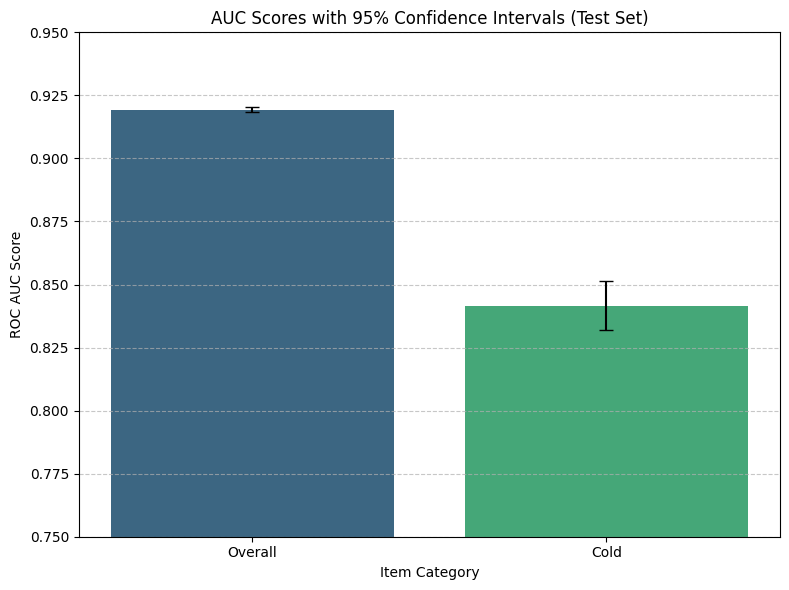

In [ ]:
# Plotting overall and cold results
fig, ax = plt.subplots(figsize=(8, 6))

sns.barplot(x='Category', y='AUC_Mean', data=df_metrics, hue='Category', palette='viridis', ax=ax, legend=False)

# Add error bars
for i, row in df_metrics.iterrows():
    ax.errorbar(i, row['AUC_Mean'],
                yerr=[[row['Error_Lower']], [row['Error_Upper']]],
                fmt='none', capsize=5, color='black', linewidth=1.5)

ax.set_title('AUC Scores with 95% Confidence Intervals (Test Set)')
ax.set_ylabel('ROC AUC Score')
ax.set_xlabel('Item Category')
ax.set_ylim(0.75, 0.95) # Adjusting y-limit for better visualization
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

The bar chart above visualizes the mean ROC AUC scores for 'Overall' and 'Cold' item interactions, with error bars representing their respective 95% bootstrapped confidence intervals.

#### Scenario-Level Metrics Comparison
(This component is made independent of the previous component to save computing units, we'll be loading the saved predictions directly)

In [ ]:
# Load from the already-saved predictions (for reproducibility)
pred_path = os.path.join(results_dir, "test_predictions.npz")
data = np.load(pred_path)

y_true = data["y_true"].astype(np.float32)
y_prob = data["y_prob"].astype(np.float32)
cold_mask = data["cold_mask"].astype(bool)
scene_idx = data["scene_idx"].astype(np.int64)

In [ ]:
unique_scenes = np.sort(np.unique(scene_idx))
print("Unique scenes:", unique_scenes)

Unique scenes: [0 1 2 3 4]


In [ ]:
# Minimum requirements for AUC: at least 50 positive and 50 negative.
MIN_POS = 50
MIN_NEG = 50

AUC is only reported for scenario subsets with at least 50 positive and 50 negative samples to avoid unstable estimates on small slices.

In [ ]:
def safe_auc_logloss(y_t, y_p):
    """Compute AUC and LogLoss with safety checks."""
    y_t = y_t.astype(np.float32)
    y_p = np.clip(y_p.astype(np.float32), 1e-7, 1 - 1e-7)

    pos = int((y_t == 1).sum())
    neg = int((y_t == 0).sum())

    out = {"auc": np.nan, "logloss": np.nan, "pos": pos, "neg": neg}
    if pos >= MIN_POS and neg >= MIN_NEG:
        out["auc"] = float(roc_auc_score(y_t, y_p))
        out["logloss"] = float(log_loss(y_t, y_p))
    else:
        # LogLoss is still computable even if AUC is not, but keeping it consistent with AUC rule
        out["logloss"] = float(log_loss(y_t, y_p)) if (pos > 0 and neg > 0) else np.nan

    return out

In [ ]:
rows = []

for s in unique_scenes:
    m_scene = (scene_idx == s)

    yt_all = y_true[m_scene]
    yp_all = y_prob[m_scene]
    n_all = int(m_scene.sum())
    pos_rate = float(yt_all.mean()) if n_all > 0 else np.nan

    all_stats = safe_auc_logloss(yt_all, yp_all)

    # Cold within scenario
    m_cold = m_scene & cold_mask
    yt_cold = y_true[m_cold]
    yp_cold = y_prob[m_cold]
    cold_stats = safe_auc_logloss(yt_cold, yp_cold) if len(yt_cold) > 0 else {"auc": np.nan, "logloss": np.nan, "pos": 0, "neg": 0}

    # Warm within scenario
    m_warm = m_scene & (~cold_mask)
    yt_warm = y_true[m_warm]
    yp_warm = y_prob[m_warm]
    warm_stats = safe_auc_logloss(yt_warm, yp_warm) if len(yt_warm) > 0 else {"auc": np.nan, "logloss": np.nan, "pos": 0, "neg": 0}

    rows.append({
        "scene": int(s),
        "N": n_all,
        "pos_rate": pos_rate,

        "AUC_all": all_stats["auc"],
        "LogLoss_all": all_stats["logloss"],
        "pos_all": all_stats["pos"],
        "neg_all": all_stats["neg"],

        "N_cold": int(m_cold.sum()),
        "pos_rate_cold": float(yt_cold.mean()) if len(yt_cold) > 0 else np.nan,
        "AUC_cold": cold_stats["auc"],
        "LogLoss_cold": cold_stats["logloss"],
        "pos_cold": cold_stats["pos"],
        "neg_cold": cold_stats["neg"],

        "N_warm": int(m_warm.sum()),
        "pos_rate_warm": float(yt_warm.mean()) if len(yt_warm) > 0 else np.nan,
        "AUC_warm": warm_stats["auc"],
        "LogLoss_warm": warm_stats["logloss"],
        "pos_warm": warm_stats["pos"],
        "neg_warm": warm_stats["neg"],
    })

In [ ]:
scenario_df = pd.DataFrame(rows).sort_values("scene").reset_index(drop=True)

In [ ]:
# Clean view for report (keeping the most important columns)
report_cols = [
    "scene", "N", "pos_rate",
    "AUC_all", "LogLoss_all",
    "N_cold", "pos_rate_cold", "AUC_cold", "LogLoss_cold",
    "N_warm", "pos_rate_warm", "AUC_warm", "LogLoss_warm",
]

display_df = scenario_df[report_cols].copy()

# rounding for readability
for c in ["pos_rate", "AUC_all", "LogLoss_all", "pos_rate_cold", "AUC_cold", "LogLoss_cold", "pos_rate_warm", "AUC_warm", "LogLoss_warm"]:
    display_df[c] = display_df[c].astype(float).round(4)

In [ ]:
print("--- Scenario-Level Metrics (Test) ---")
print(display_df.to_string(index=False))

--- Scenario-Level Metrics (Test) ---
 scene      N  pos_rate  AUC_all  LogLoss_all  N_cold  pos_rate_cold  AUC_cold  LogLoss_cold  N_warm  pos_rate_warm  AUC_warm  LogLoss_warm
     0  21682    0.0412   0.8834       0.1220    4666         0.0769    0.7956        0.2229   17016         0.0314    0.9001        0.0943
     1  91798    0.2317   0.9391       0.2602    2199         0.1128    0.8298        0.2692   89599         0.2346    0.9400        0.2600
     2 189948    0.4674   0.9155       0.3673    2303         0.2319    0.8372        0.4010  187645         0.4703    0.9157        0.3669
     3  42514    0.2974   0.6891       0.5631    3029         0.2757    0.7109        0.5374   39485         0.2991    0.6873        0.5651
     4  27091    0.0745   0.8296       0.2048    2342         0.0273    0.7732        0.1064   24749         0.0790    0.8265        0.2141


##### **Overall AUC per scenario**
From strongest to weakest:
* Scenario 1: 0.939
* Scenario 2: 0.916
* Scenario 0: 0.883
* Scenario 4: 0.830
* Scenario 3: 0.689


In [ ]:
scenario_csv_path = os.path.join(results_dir, "scenario_metrics.csv")
scenario_df.to_csv(scenario_csv_path, index=False)

print("Saved scenario_metrics.csv to:", scenario_csv_path)

Saved scenario_metrics.csv to: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/eval_results/scenario_metrics.csv


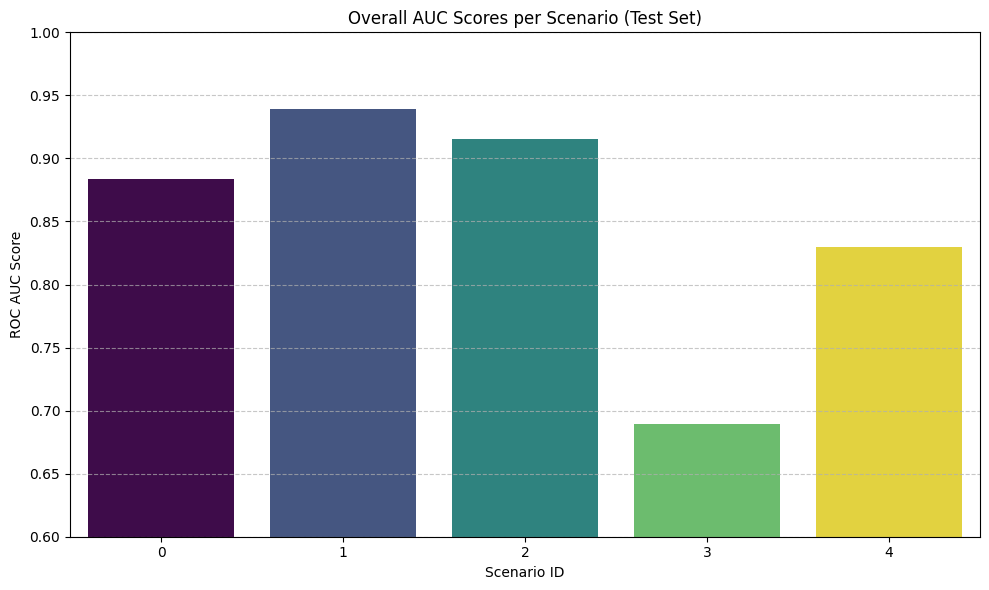

In [ ]:
# Plotting overall AUC per scenario
plt.figure(figsize=(10, 6))
sns.barplot(x='scene', y='AUC_all', data=scenario_df, hue='scene', palette='viridis', legend=False)
plt.title('Overall AUC Scores per Scenario (Test Set)')
plt.xlabel('Scenario ID')
plt.ylabel('ROC AUC Score')
plt.ylim(0.6, 1.0) # Adjust y-limit to better visualize differences
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Scenario-level evaluation shows consistently strong performance in scenarios (AUC > 0.91 in Scenarios 1–2) and strong cold-start generalisation across all scenarios, while lower AUC in Scenario 3 reflects intrinsic scenario difficulty rather than cold-start degradation since both cold and warm degrade similarly.

#### Alpha Diagnostics (Cold/Warm Pipeline Evidence)
(This component is made independent of the previous component to save computing units, we'll be loading the saved predictions directly)

In [ ]:
# Load predictions
pred_path = os.path.join(results_dir, "test_predictions.npz")
data = np.load(pred_path)

In [ ]:
alpha = data["alpha"].astype(np.float32).squeeze()   # (N,)
cold_mask = data["cold_mask"].astype(bool)
scene_idx = data["scene_idx"].astype(np.int64)

# Basic stats
unique_alpha_count = len(np.unique(alpha))

In [ ]:
print("--- Alpha Diagnostics Summary ---")
print(f"Alpha shape: {alpha.shape}")
print(f"Unique alpha values: {unique_alpha_count}")
print(f"Alpha min / max / mean: {alpha.min():.4f} / {alpha.max():.4f} / {alpha.mean():.4f}")

print("\nAlpha by split:")
print(f"  Cold  mean α: {alpha[cold_mask].mean():.4f}")
print(f"  Warm  mean α: {alpha[~cold_mask].mean():.4f}")

--- Alpha Diagnostics Summary ---
Alpha shape: (373033,)
Unique alpha values: 11
Alpha min / max / mean: 0.0000 / 1.0000 / 0.9831

Alpha by split:
  Cold  mean α: 0.5677
  Warm  mean α: 1.0000


Note: α takes 11 discrete values because it is computed from train-only item counts clipped at FEWSHOT_N=10 (counts 0–10 map to distinct α; counts >10 saturate to α=1).

The distribution of α demonstrates a smooth, frequency-driven transition between meta-based representations for cold items and ID-based representations for warm items, confirming that ColdFusionX implements a unified and continuous cold–warm learning pipeline rather than a hard switch.

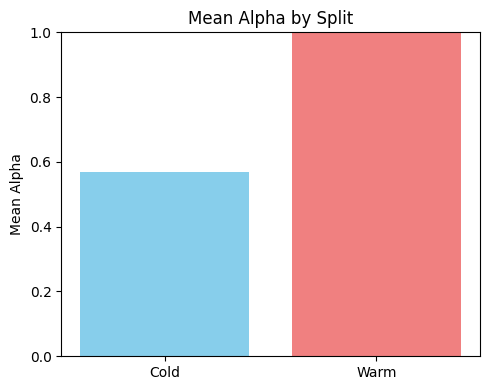

In [ ]:
# Alpha by split (Cold vs Warm)
alpha_means = {
    "Cold": alpha[cold_mask].mean(),
    "Warm": alpha[~cold_mask].mean()
}

plt.figure(figsize=(5, 4))
plt.bar(alpha_means.keys(), alpha_means.values(), color=['skyblue', 'lightcoral'])
plt.ylabel("Mean Alpha")
plt.title("Mean Alpha by Split")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [ ]:
# Alpha by scenario
unique_scenes = np.sort(np.unique(scene_idx))
alpha_scene_means = []

for s in unique_scenes:
    alpha_scene_means.append(alpha[scene_idx == s].mean())

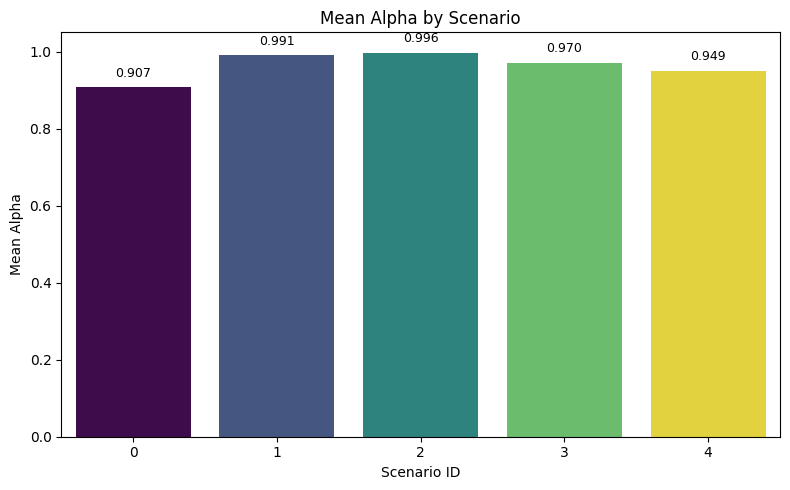

In [ ]:
# Plotting Mean Alpha values by scenario
plt.figure(figsize=(8, 5))
sns.barplot(x=unique_scenes, y=alpha_scene_means, hue=unique_scenes, palette='viridis', legend=False)
plt.xlabel("Scenario ID")
plt.ylabel("Mean Alpha")
plt.title("Mean Alpha by Scenario")
plt.ylim(0, 1.05) # Adjust y-limit to accommodate annotations

# Add value annotations on top of the bars
for i, val in enumerate(alpha_scene_means):
    plt.text(i, val + 0.02, f'{val:.3f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

Alpha diagnostics confirm a smooth, frequency-driven transition between meta-based and ID-based representations, with cold interactions showing substantially lower α values than warm interactions, validating the proposed unified cold–warm blending mechanism.

#### Ablation Study (Inference-time Diagnostic)

In [ ]:
def split_metrics(y_true, y_prob, cold_mask):
    overall = compute_metrics(y_true, y_prob) # defined earlier
    cold = compute_metrics(y_true[cold_mask], y_prob[cold_mask]) if cold_mask.sum() > 0 else {"auc": np.nan, "logloss": np.nan, "accuracy": np.nan}
    warm = compute_metrics(y_true[~cold_mask], y_prob[~cold_mask]) if (~cold_mask).sum() > 0 else {"auc": np.nan, "logloss": np.nan, "accuracy": np.nan}
    return overall, cold, warm

In [ ]:
# Load baseline (Full model) predictions from Step 5
pred_path = os.path.join(results_dir, "test_predictions.npz")
base = np.load(pred_path)

y_true_base = base["y_true"].astype(np.float32)
y_prob_base = base["y_prob"].astype(np.float32)
cold_mask_base = base["cold_mask"].astype(bool)

overall_base, cold_base, warm_base = split_metrics(y_true_base, y_prob_base, cold_mask_base)

print("Loaded Full model baseline from test_predictions.npz")
print("Full Overall:", overall_base)
print("Full Cold   :", cold_base)
print("Full Warm   :", warm_base)

Loaded Full model baseline from test_predictions.npz
Full Overall: {'auc': 0.9193886281111345, 'logloss': 0.33721302231322986, 'accuracy': 0.8512195971938139}
Full Cold   : {'auc': 0.8418015794204712, 'logloss': 0.30488615488931625, 'accuracy': 0.8774331109429809}
Full Warm   : {'auc': 0.919951518893816, 'logloss': 0.3385240632943238, 'accuracy': 0.8501564879746941}


In [ ]:
def stable_sigmoid_np(x: np.ndarray) -> np.ndarray:
    """
    Numerically stable sigmoid function for NumPy arrays.

    This function computes the sigmoid of each element in a NumPy array `x`
    in a numerically stable way, preventing overflow or underflow issues
    for very large positive or negative input values.

    Args:
        x (np.ndarray): The input NumPy array.

    Returns:
        np.ndarray: A NumPy array containing the sigmoid of each element in `x`,
                    with values between 0 and 1.
    """
    out = np.empty_like(x, dtype=np.float32)
    pos = x >= 0
    neg = ~pos
    out[pos] = 1.0 / (1.0 + np.exp(-x[pos]))
    exp_x = np.exp(x[neg])
    out[neg] = exp_x / (1.0 + exp_x)
    return out

In [ ]:
def run_inference_collect_probs(model, loader, device):
    """
    Runs predictions on the provided DataLoader and collects true labels, predicted probabilities,
    and cold item masks. This function is designed for evaluation and ablation studies.

    Args:
        model (torch.nn.Module): The PyTorch model to evaluate.
        loader (torch.utils.data.DataLoader): DataLoader providing batches of data.
        device (str): The device ('cuda' or 'cpu') to run the inference on.

    Returns:
        Tuple[np.ndarray, np.ndarray, np.ndarray]:
            - y_true (np.ndarray): Array of true labels.
            - y_prob (np.ndarray): Array of predicted probabilities.
            - cold_mask (np.ndarray): Boolean mask indicating cold items.
    """
    model.eval()
    logits_list = []
    ytrue_list = []
    cold_list = []

    with torch.no_grad():
        for batch in tqdm(loader, desc="Ablation inference"):
            logits = model(
                user_idx=batch["user_idx"].to(device, non_blocking=True),
                item_idx=batch["item_idx"].to(device, non_blocking=True),
                scene_idx=batch["scene_idx"].to(device, non_blocking=True),
                text_vec=batch["text_vec"].to(device, non_blocking=True),
                image_vec=batch["image_vec"].to(device, non_blocking=True),
                time_vec=batch["time_vec"].to(device, non_blocking=True),
                cold_mask=batch["cold_mask"].to(device, non_blocking=True),
                item_count=batch["item_count"].to(device, non_blocking=True),
            )

            logits_list.append(logits.detach().float().cpu().numpy())
            ytrue_list.append(batch["label"].detach().float().cpu().numpy())
            cold_list.append(batch["cold_mask"].detach().cpu().numpy().astype(np.bool_))

    y_logit = np.concatenate(logits_list).astype(np.float32)
    y_true = np.concatenate(ytrue_list).astype(np.float32)
    cold_mask = np.concatenate(cold_list).astype(np.bool_)
    y_prob = stable_sigmoid_np(y_logit)

    assert len(y_true) == len(test_idx), "Inference size mismatch vs test_idx"
    return y_true, y_prob, cold_mask

Ablation variants via safe monkey-patching (no retraining)
*   We temporarily override parts of the trained model at inference, then restores them.


In [ ]:
def evaluate_variant(name, patch_fn=None):
    """
    Evaluates a model variant by running inference and computing metrics.

    Args:
        name (str): Name of the variant.
        patch_fn (callable, optional): Function to temporarily modify the model for the variant.

    Returns:
        dict: A dictionary containing various evaluation metrics for the variant.
    """
    restore_fn = None
    if patch_fn is not None:
        restore_fn = patch_fn(model)

    y_true, y_prob, cold_mask = run_inference_collect_probs(model, test_loader, device)

    if restore_fn is not None:
        restore_fn()

    overall, cold, warm = split_metrics(y_true, y_prob, cold_mask)

    return {
        "variant": name,
        "auc_all": overall["auc"],
        "logloss_all": overall["logloss"],
        "acc_all": overall["accuracy"],
        "auc_cold": cold["auc"],
        "logloss_cold": cold["logloss"],
        "acc_cold": cold["accuracy"],
        "auc_warm": warm["auc"],
        "logloss_warm": warm["logloss"],
        "acc_warm": warm["accuracy"],
        "N_total": int(len(y_true)),
        "N_cold": int(cold_mask.sum()),
        "N_warm": int((~cold_mask).sum()),
    }

In [ ]:
# --- Patch 1: No Meta Embedding (force item_final = item_id_emb; alpha ≡ 1) ---
def patch_no_meta(model):
    orig_blender_forward = model.blender.forward

    def blender_forward_no_meta(self, item_id_emb, item_meta_emb, item_count):
        alpha = torch.ones((item_id_emb.size(0), 1), device=item_id_emb.device, dtype=item_id_emb.dtype)
        self._last_alpha = alpha.detach()
        return item_id_emb  # ignore meta completely

    model.blender.forward = types.MethodType(blender_forward_no_meta, model.blender)

    def restore():
        model.blender.forward = orig_blender_forward

    return restore


In [ ]:
# --- Patch 2: No Scenario Routing (bypass gating: use Expert-0 only) ---
def patch_no_routing(model):
    orig_mmoe_forward = model.mmoe.forward

    def mmoe_forward_expert0(self, x, scene_idx):
        y = self.experts[0](x)  # (B, hidden_dim)
        # Store a deterministic "gate" diagnostic (all mass on expert0)
        gates = torch.zeros((x.size(0), self.num_experts), device=x.device, dtype=x.dtype)
        gates[:, 0] = 1.0
        self._last_gates = gates.detach()
        return y

    model.mmoe.forward = types.MethodType(mmoe_forward_expert0, model.mmoe)

    def restore():
        model.mmoe.forward = orig_mmoe_forward

    return restore

In [ ]:
# --- Patch 3: No Modality Attention (uniform mean over projected modalities) ---
def patch_no_modality_attention(model):
    orig_fusion_forward = model.fusion.forward

    def fusion_forward_mean(self, id_vec, text_vec, image_vec, time_vec):
        z_id = self.proj_id(id_vec)
        z_text = self.proj_text(text_vec)
        z_image = self.proj_image(image_vec)
        z_time = self.proj_time(time_vec)

        fused = (z_id + z_text + z_image + z_time) / 4.0

        # Store uniform weights as "attention"
        B = fused.size(0)
        attn = torch.full((B,), 0.25, device=fused.device, dtype=fused.dtype)
        self._last_attention = {"id": attn.detach(), "text": attn.detach(), "image": attn.detach(), "time": attn.detach()}

        return fused

    model.fusion.forward = types.MethodType(fusion_forward_mean, model.fusion)

    def restore():
        model.fusion.forward = orig_fusion_forward

    return restore

##### Run ablations + build table + deltas + save CSV

In [ ]:
results = []

# Full model: baseline metrics from saved arrays (without rerun)
results.append({
    "variant": "Full (Saved)",
    "auc_all": overall_base["auc"], "logloss_all": overall_base["logloss"], "acc_all": overall_base["accuracy"],
    "auc_cold": cold_base["auc"], "logloss_cold": cold_base["logloss"], "acc_cold": cold_base["accuracy"],
    "auc_warm": warm_base["auc"], "logloss_warm": warm_base["logloss"], "acc_warm": warm_base["accuracy"],
    "N_total": int(len(y_true_base)),
    "N_cold": int(cold_mask_base.sum()),
    "N_warm": int((~cold_mask_base).sum()),
})

In [ ]:
# No Meta Embedding
results.append(evaluate_variant("No Meta (α≡1)", patch_no_meta))

# No Scenario Routing (Expert-0 only)
results.append(evaluate_variant("No Routing (Expert0)", patch_no_routing))

# No Modality Attention
results.append(evaluate_variant("No Modality Attn (Mean)", patch_no_modality_attention))

ablation_df = pd.DataFrame(results)

Ablation inference:   0%|          | 0/92 [00:00<?, ?it/s]

Ablation inference:   0%|          | 0/92 [00:00<?, ?it/s]

Ablation inference:   0%|          | 0/92 [00:00<?, ?it/s]

In [ ]:
# Deltas vs Full
full_row = ablation_df.iloc[0]
for col in ["auc_all", "logloss_all", "acc_all", "auc_cold", "logloss_cold", "acc_cold", "auc_warm", "logloss_warm", "acc_warm"]:
    ablation_df[f"delta_{col}"] = ablation_df[col] - float(full_row[col])

In [ ]:
# Round for readability
metric_cols = [c for c in ablation_df.columns if c.startswith(("auc", "logloss", "acc", "delta_"))]
ablation_df[metric_cols] = ablation_df[metric_cols].astype(float).round(4)

print("Ablation Study (Inference-time Diagnostic)")
print(ablation_df.to_string(index=False))

Ablation Study (Inference-time Diagnostic)
                variant  auc_all  logloss_all  acc_all  auc_cold  logloss_cold  acc_cold  auc_warm  logloss_warm  acc_warm  N_total  N_cold  N_warm  delta_auc_all  delta_logloss_all  delta_acc_all  delta_auc_cold  delta_logloss_cold  delta_acc_cold  delta_auc_warm  delta_logloss_warm  delta_acc_warm
           Full (Saved)   0.9194       0.3372   0.8512    0.8418        0.3049    0.8774    0.9200        0.3385    0.8502   373033   14539  358494         0.0000             0.0000         0.0000          0.0000              0.0000          0.0000          0.0000              0.0000          0.0000
          No Meta (α≡1)   0.9192       0.3376   0.8511    0.8258        0.3151    0.8739    0.9200        0.3385    0.8502   373033   14539  358494        -0.0002             0.0004        -0.0001         -0.0160              0.0102         -0.0036          0.0000              0.0000          0.0000
   No Routing (Expert0)   0.9118       0.3779   0.8247

The ablation study confirms that each component contributes in a targeted and theoretically consistent manner.
* Removing meta embeddings primarily degrades cold-start performance
* Scenario-aware routing improves both cold and warm predictions by modelling heterogeneous traffic patterns.
* Modality attention proves particularly critical under cold-start conditions, where uniform modality aggregation leads to the largest performance drop.

Together, these results validate that ColdFusionX’s gains arise from complementary and non-redundant design choices rather than incidental model capacity.

In [ ]:
# Save CSV
ablation_path = os.path.join(results_dir, "ablation_metrics.csv")
ablation_df.to_csv(ablation_path, index=False)
print("Saved ablation_metrics.csv to:", ablation_path)

Saved ablation_metrics.csv to: /content/drive/MyDrive/Final_Year_Project/Implementation/datasets/AntM2C_10M/eval_results/ablation_metrics.csv


In [ ]:
!git add .


Refresh index: 100% (14/14), done.
